# Titanic Analysis: Age, Fare and Survival
**Week 2 – Assignment 2**

**Goal:** analyse the relationship between **age**, **fare** and **survival** in the Titanic dataset, and include **correlation heatmaps**.

**Plan**
1. Load and inspect the data
2. Clean the data (missing values)
3. A quick sanity check of the data (important – see section 3)
4. Look at each variable on its own (univariate)
5. Age vs survival, fare vs survival, age vs fare (bivariate)
6. Correlation heatmaps
7. Conclusions

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")   # clean grid background + soft colours
plt.rcParams["figure.figsize"] = (7, 4)            # default size for single plots

df = pd.read_csv("titanic.csv")   # read the CSV into a DataFrame
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (418, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [2]:
# .info() shows each column's data type and how many non-null values it has
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 39.3 KB


In [3]:
# Count missing values per column
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

**What we see:** the dataset has 418 passengers and 12 columns.
- `Age` is missing for 86 passengers (about 21%).
- `Fare` is missing for just 1 passenger.
- `Cabin` is missing for 327 passengers (about 78%), too many to be useful, and we don't need it for this question.

## 2. Data cleaning

In [4]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Keep a copy of the original Age so we can compare before/after filling
df["Age_original"] = df["Age"]

# --- Fill missing Age ---
# Age clearly differs by passenger class and sex, so instead of one global average
# we use the MEDIAN age of each (Pclass, Sex) group. Median is used because it is
# not affected by a few very old/young passengers.
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda s: s.fillna(s.median()))

# --- Fill the single missing Fare ---
# Fare depends strongly on class, so use the median fare of that passenger's class.
df["Fare"] = df["Fare"].fillna(df.groupby("Pclass")["Fare"].transform("median"))

# --- Drop Cabin ---
# ~78% missing, so filling it would mostly be guessing. Not needed for this analysis.
df = df.drop(columns=["Cabin"])

print("Missing Age :", df["Age"].isnull().sum())
print("Missing Fare:", df["Fare"].isnull().sum())

Duplicate rows: 0
Missing Age : 0
Missing Fare: 0


In [5]:
# Does filling Age change the picture? Compare summary stats before and after.
print(df[["Age_original", "Age"]].describe().round(2))

# Two passengers have Fare = 0. These are probably crew/free tickets, not errors, so we keep them.
print("\nPassengers with Fare = 0:", (df["Fare"] == 0).sum())

       Age_original     Age
count        332.00  418.00
mean          30.27   29.30
std           14.18   13.04
min            0.17    0.17
25%           21.00   22.00
50%           27.00   25.00
75%           39.00   36.38
max           76.00   76.00

Passengers with Fare = 0: 2


**Cleaning decisions**
- **Age:** filled with the median of the passenger's class and sex group. After filling, the mean drops by about 1 year (30.3 to 29.3) and the spread shrinks a little (std 14.2 to 13.0). This is expected when missing values are replaced with typical values, and the overall shape stays the same.
- **Fare:** only 1 missing value, filled with the class median.
- **Cabin:** dropped (too many missing values).
- **Fare = 0:** kept, since it is a plausible real value.

## 3. Important data check: how is `Survived` related to `Sex`?

Before analysing survival, it is good practice to check that the target column looks sensible.

In [6]:
# Cross-tabulation: counts of survived / not survived for each sex
print(pd.crosstab(df["Sex"], df["Survived"]))

# What share of passengers have Survived == 1 exactly when they are female?
match = (df["Survived"] == (df["Sex"] == "female").astype(int)).mean()
print(f"\nSurvived matches 'is female' for {match:.0%} of passengers")

Survived    0    1
Sex               
female      0  152
male      266    0

Survived matches 'is female' for 100% of passengers


**Important finding:** in this file **every woman is marked as survived and every man as not survived**, a 100% match. Real Titanic outcomes were not that clean-cut (some women died and some men survived). This `titanic.csv` is the Kaggle *test* set combined with the "all women survive" baseline predictions, so the `Survived` column is a **simple rule, not real historical outcomes**.

**What this means for the rest of the analysis**
- Anything we find about `Survived` will mostly reflect **sex**, not age or fare themselves.
- Relationships that don't involve `Survived` (for example age vs fare vs class) are still real, as they come from actual passenger records.
- I still do the analysis the assignment asks for, and I point out below where a result is just a side effect of this rule.
- Using Kaggle's real `train.csv` (891 passengers) would give meaningful survival results, and the same code would work on it.

## 4. Univariate analysis (one variable at a time)

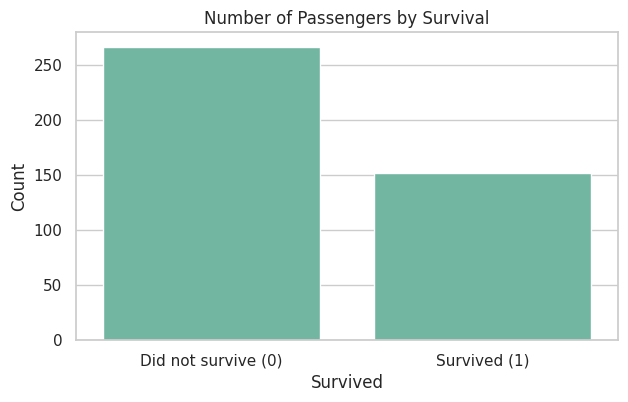

Survived
0    0.636
1    0.364
Name: proportion, dtype: float64


In [7]:
# How many passengers are marked survived vs not?
ax = sns.countplot(data=df, x="Survived")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive (0)", "Survived (1)"])
ax.set_title("Number of Passengers by Survival")
ax.set_ylabel("Count")
plt.show()

print(df["Survived"].value_counts(normalize=True).round(3))

In this data about 36% of passengers are marked as survived and 64% as not survived.

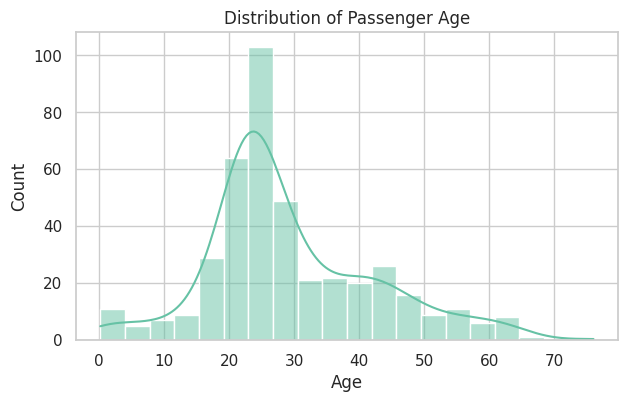

count    418.00
mean      29.30
std       13.04
min        0.17
25%       22.00
50%       25.00
75%       36.38
max       76.00
Name: Age, dtype: float64


In [8]:
# Distribution of Age
sns.histplot(data=df, x="Age", bins=20, kde=True)   # kde=True draws a smooth density line
plt.title("Distribution of Passenger Age")
plt.show()

print(df["Age"].describe().round(2))

Most passengers are young adults (roughly 20 to 40). The ages go from under 1 year to 76, with a long thin tail of older passengers.

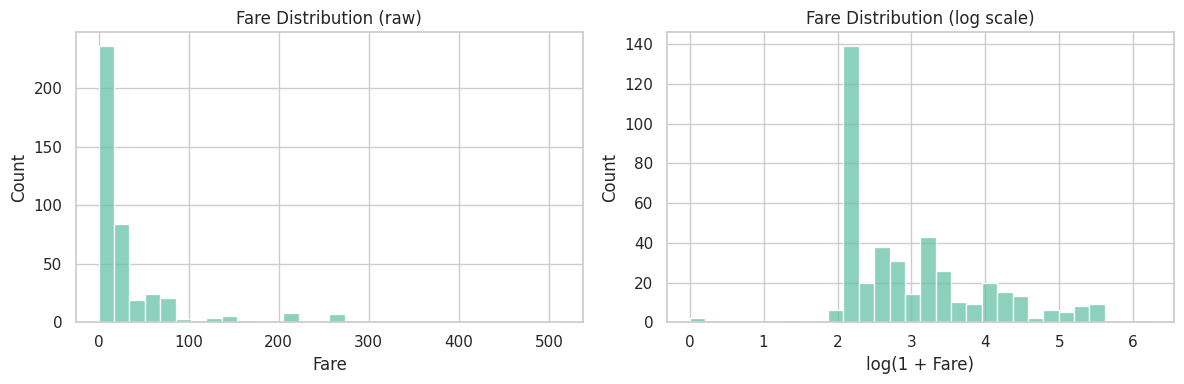

Skewness of Fare    : 3.69
Skewness of log Fare: 0.87


In [9]:
# Distribution of Fare: raw scale vs log scale side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="Fare", bins=30, ax=axes[0])
axes[0].set_title("Fare Distribution (raw)")

sns.histplot(x=np.log1p(df["Fare"]), bins=30, ax=axes[1])   # log1p = log(1 + x), safe for Fare = 0
axes[1].set_title("Fare Distribution (log scale)")
axes[1].set_xlabel("log(1 + Fare)")

plt.tight_layout()
plt.show()

print("Skewness of Fare    :", round(df["Fare"].skew(), 2))
print("Skewness of log Fare:", round(np.log1p(df["Fare"]).skew(), 2))

Fare is **heavily right-skewed**: most passengers paid small fares and a few paid very large ones (up to about 512). Taking the logarithm makes the distribution much more symmetric (skewness drops from about 3.7 to about 0.9), so we use a log scale for fare in later plots.

## 5. Bivariate analysis

### 5.1 Age vs survival

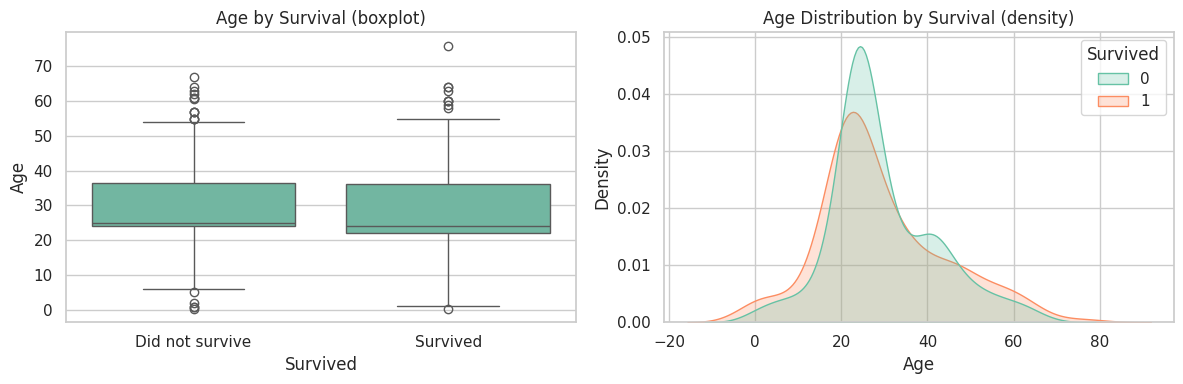

           mean  median
Survived               
0         29.37    25.0
1         29.17    24.0


In [10]:
# Compare the age distribution of survivors vs non-survivors
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Survived", y="Age", ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Did not survive", "Survived"])
axes[0].set_title("Age by Survival (boxplot)")

sns.kdeplot(data=df, x="Age", hue="Survived", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("Age Distribution by Survival (density)")

plt.tight_layout()
plt.show()

print(df.groupby("Survived")["Age"].agg(["mean", "median"]).round(2))

**Interpretation:** the two age distributions almost completely overlap, and the average ages are nearly identical (about 29 years for both groups). So **age on its own shows essentially no relationship with survival** in this data. This fits what we found in section 3: survival here depends on sex, and men and women in this data have almost the same average age (about 29 years each after filling).

                     survival_rate  passengers
AgeGroup                                      
Child (0-12)                 0.480          25
Teen (13-18)                 0.414          29
Young adult (19-35)          0.340         250
Adult (36-60)                0.379         103
Senior (60+)                 0.364          11


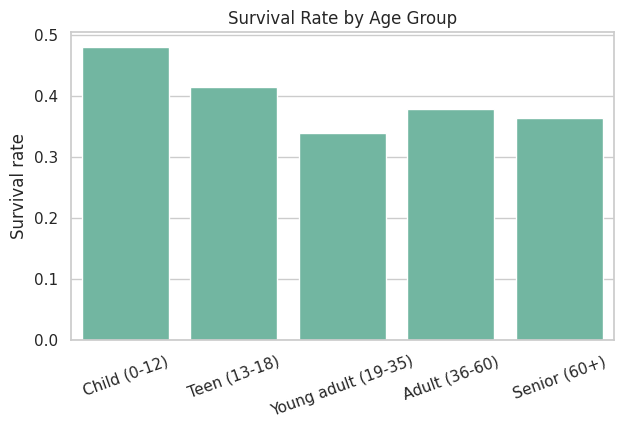

In [11]:
# Survival rate for different age groups
df["AgeGroup"] = pd.cut(df["Age"],
                        bins=[0, 12, 18, 35, 60, 100],
                        labels=["Child (0-12)", "Teen (13-18)", "Young adult (19-35)", "Adult (36-60)", "Senior (60+)"])

age_summary = df.groupby("AgeGroup", observed=True)["Survived"].agg(survival_rate="mean", passengers="count").round(3)
print(age_summary)

sns.barplot(data=df, x="AgeGroup", y="Survived", errorbar=None)   # bar height = survival rate
plt.title("Survival Rate by Age Group")
plt.ylabel("Survival rate")
plt.xlabel("")
plt.xticks(rotation=20)
plt.show()

**Interpretation:** the survival rate varies only a little across age groups (roughly 34% to 48%). Children have the highest rate, but there are only 25 children, and only 11 seniors, so those two bars are based on very few passengers and should not be over-interpreted. There is no clear age pattern.

### 5.2 Fare vs survival

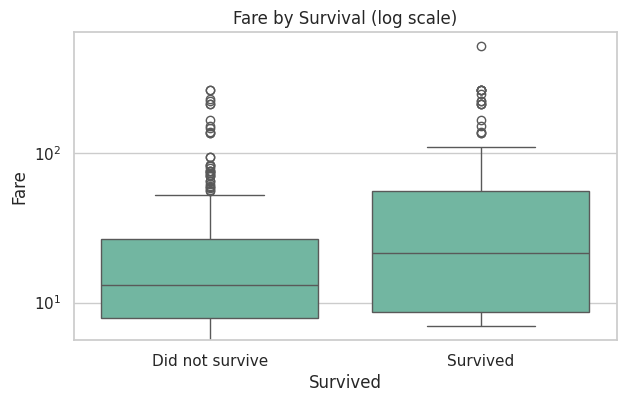

           mean  median
Survived               
0         27.45   13.00
1         49.75   21.51


In [12]:
# Compare fares of survivors vs non-survivors (log scale because Fare is so skewed)
sns.boxplot(data=df, x="Survived", y="Fare")
plt.yscale("log")
plt.xticks([0, 1], ["Did not survive", "Survived"])
plt.title("Fare by Survival (log scale)")
plt.show()

print(df.groupby("Survived")["Fare"].agg(["mean", "median"]).round(2))

**Interpretation:** survivors paid higher fares: the **median fare is about 21.5 for survivors vs 13.0 for non-survivors**, and the mean is about 49.7 vs 27.5. So higher fare goes together with being marked as survived.

**But be careful:** the reason is not necessarily that money "saved" people. In this data survivors are exactly the women, and women in this dataset paid higher fares on average (about 49.7 vs 27.5 for men). The next chart helps show this.

              survival_rate  share_female  passengers
FareBand                                             
Q1 (lowest)           0.261         0.261         115
Q2                    0.271         0.271          96
Q3                    0.402         0.402         102
Q4 (highest)          0.524         0.524         105


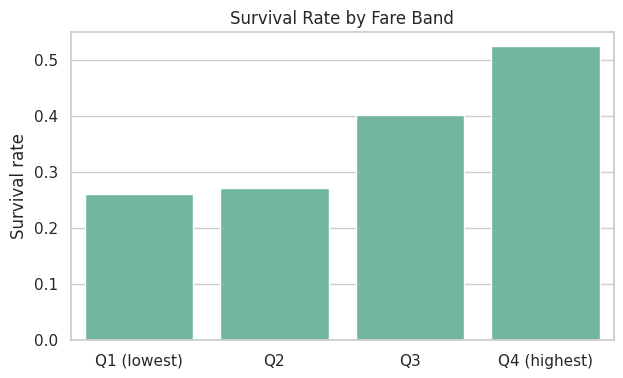

In [13]:
# Split passengers into 4 equal-sized fare bands (quartiles) and look at survival rate in each
df["FareBand"] = pd.qcut(df["Fare"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

fare_summary = df.groupby("FareBand", observed=True).agg(
    survival_rate=("Survived", "mean"),
    share_female=("Sex", lambda s: (s == "female").mean()),
    passengers=("Survived", "count")
).round(3)
print(fare_summary)

sns.barplot(data=df, x="FareBand", y="Survived", errorbar=None)
plt.title("Survival Rate by Fare Band")
plt.ylabel("Survival rate")
plt.xlabel("")
plt.show()

**Interpretation:** survival rate rises steadily from about 26% in the cheapest fare band to about 52% in the most expensive one. Look at the table: the **survival rate in each band is exactly equal to the share of women in that band**. That confirms that the fare effect here is just the sex effect in disguise: higher-fare bands simply contain more women.

### 5.3 Age vs fare

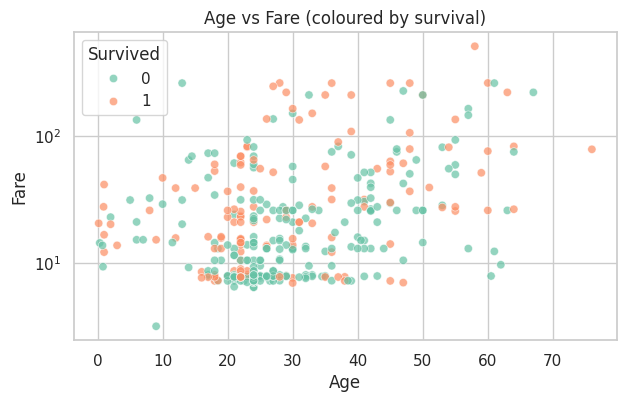

         Age   Fare
Pclass             
1       42.0  60.00
2       27.0  15.75
3       24.0   7.90


In [14]:
# Scatter plot of Age vs Fare, coloured by survival
sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived", alpha=0.7)
plt.yscale("log")
plt.title("Age vs Fare (coloured by survival)")
plt.show()

# Also look at the numbers by passenger class
print(df.groupby("Pclass")[["Age", "Fare"]].median().round(2))

**Interpretation:** there is a **weak positive relationship between age and fare**: older passengers tend to pay somewhat more (correlation about 0.35, see the heatmap below). The class table shows why: first-class passengers are older (median 42) and paid much more (median fare 60) than third-class passengers (median age 24, median fare about 7.9). So **passenger class links age and fare together**.

## 6. Correlation heatmaps

A **correlation** measures how strongly two numeric columns move together, from -1 (opposite directions) to +1 (same direction). 0 means no linear relationship.
- **Pearson** measures linear relationships.
- **Spearman** is based on ranks, so it is less affected by outliers and skewed data like Fare.

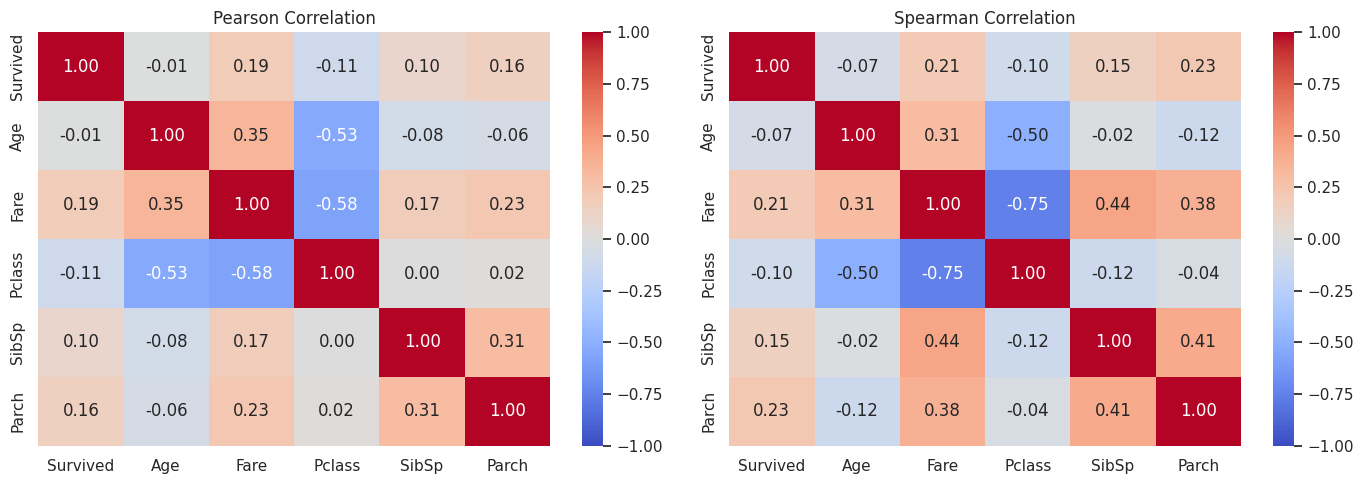

In [15]:
cols = ["Survived", "Age", "Fare", "Pclass", "SibSp", "Parch"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df[cols].corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson Correlation")

sns.heatmap(df[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

**How to read the heatmaps**
- **Age vs Survived ≈ 0 (-0.01):** no linear relationship between age and survival.
- **Fare vs Survived ≈ +0.19 to +0.21:** a weak positive relationship (higher fare, more likely marked as survived). From section 5.2 we know this is mostly the sex effect.
- **Fare vs Pclass = -0.58 (Pearson) and -0.75 (Spearman):** a strong negative relationship. Class 1 is the highest class, so a *lower* class number means a *higher* fare. Spearman is stronger because the relationship is not a straight line.
- **Age vs Pclass = -0.53:** higher-class passengers are older, which is why Age and Fare are positively correlated (+0.35).
- **Age vs Fare = +0.35 (Pearson) and +0.31 (Spearman):** a moderate positive relationship, mainly explained by class.

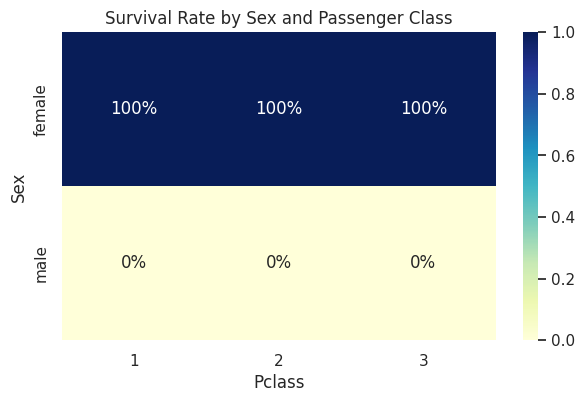

In [16]:
# Last check: survival rate by Sex and Pclass (this makes the 'Survived = female' pattern visible)
pivot = df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")

sns.heatmap(pivot, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival Rate by Sex and Passenger Class")
plt.show()

Women have a 100% survival rate and men 0% in **every** class. Real Titanic data would show big differences between classes, so this confirms that the `Survived` column in this file is a simple rule.

## 7. Conclusions

| Question | Finding |
|---|---|
| **Age and survival** | No relationship: average age is about the same for both groups, the correlation is about 0, and survival rates are similar across age groups. |
| **Fare and survival** | Survivors paid more (median 21.5 vs 13.0; correlation about +0.2), but this is explained by sex, because women both "survive" in this data and paid higher fares. |
| **Age and fare** | Moderate positive relationship (about +0.35), driven by passenger class: first-class passengers are older and paid far more. |
| **Strongest relationship overall** | Fare and passenger class (Pearson -0.58, Spearman -0.75). |
| **Fare distribution** | Heavily right-skewed. A log scale is needed for clear plots. |

**Main takeaways**
1. Passenger **class** is the factor that connects age and fare.
2. In this specific file, survival is determined entirely by **sex**, so age and fare cannot add anything to it. The weak fare-survival link is an indirect effect.
3. To study how age and fare *really* affected survival, repeat this notebook with Kaggle's `train.csv` (891 passengers with true outcomes); only the filename needs to change.